# 04 · Comparative Analysis and Results
**Components 4 and 5: comparative performance analysis, interpretation, limitations.** Run notebooks 01, 02 and 03 first.

Reads `dataset/` and `Unit_3_PBL2_Clustering_KMeans/results/02_clustering/`, `Unit_4_PBL2_HMM/results/03_hmm/` · creates `Unit_4_PBL2_HMM/results/04_comparison/`.

In [1]:
# ---- Only on Google Colab (skip on your own computer) ----
# !pip install -q hmmlearn
# from google.colab import drive; drive.mount("/content/drive")
# %cd /content/drive/MyDrive/QuickCommerce_ML_Project_Final

import os, json, time, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

# project root = the folder that contains data/ and dataset/ (works from the unit folder, the root or Colab)
if not os.path.isdir("data") and os.path.isdir(os.path.join("..", "data")):
    os.chdir("..")
print("Working folder:", os.getcwd())
warnings.filterwarnings("ignore")
logging.getLogger("hmmlearn").setLevel(logging.ERROR)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42
DATE = "%d-%m-%Y"

def inr(x):
    # Indian digit grouping: 113390 -> 1,13,390
    s = f"{abs(x):.0f}"; head, tail = s[:-3], s[-3:]; parts = []
    while len(head) > 2:
        parts.insert(0, head[-2:]); head = head[:-2]
    if head: parts.insert(0, head)
    return ("-" if x < 0 else "") + ",".join(parts + [tail])

# chart style — colour-blind-safe palette in fixed order
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 9.5, "font.size": 8.5, "axes.labelsize": 8.5,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 1.5, "figure.dpi": 110, "legend.frameon": False,
})

OUT = "Unit_4_PBL2_HMM/results/04_comparison"                      # every file this notebook creates goes here
os.makedirs(OUT, exist_ok=True)
def save_fig(fig, name):
    fig.savefig(f"{OUT}/{name}.png", dpi=240, bbox_inches="tight")
    plt.show()

Working folder: /home/claude/project


In [2]:
stores = pd.read_csv("Unit_3_PBL2_Clustering_KMeans/results/02_clustering/store_clusters.csv", index_col="store_id")
daily = pd.read_csv("Unit_4_PBL2_HMM/results/03_hmm/daily_regimes.csv", index_col="order_date", parse_dates=["order_date"])
clean = pd.read_csv("dataset/clean_food_orders.csv", parse_dates=["order_date"])
km_sum = json.load(open("Unit_3_PBL2_Clustering_KMeans/results/02_clustering/summary.json"))
hmm_sum = json.load(open("Unit_4_PBL2_HMM/results/03_hmm/summary.json"))
ORDER = ["Family residential stores", "Late-night snack hubs", "Daytime office stores"]
SORDER = ["Normal", "Monsoon / disrupted", "Festival peak"]
SCOL = dict(zip(SORDER, [BLUE, AQUA, ORANGE]))
print("Loaded:", len(stores), "stores with clusters |", len(daily), "days with regimes |", inr(len(clean)), "orders")

Loaded: 58 stores with clusters | 638 days with regimes | 1,13,390 orders


## 4.1 Comparison of the two methods
| Aspect | K-Means clustering | Hidden Markov Model |
|---|---|---|
| Objective | group **similar dark stores** | find **hidden regimes over time** and how they switch |
| Input | one row per store (58 × 10 features), no time order | ordered sequence of days (638 × 2 observations) |
| Learning | unsupervised, minimises within-cluster distance | unsupervised, maximises likelihood (Baum–Welch / EM) |
| Uses time order? | no | **yes** (Markov transitions) |
| Output | cluster label + centre profile per store | π, A, B, decoded state per day, next-day forecast |
| Evaluation | silhouette, Davies–Bouldin, Calinski–Harabasz, stability | log-likelihood, AIC/BIC, out-of-sample likelihood, festival recall |
| Supply-chain use | *where* — store-specific stocking & staffing | *when* — regime-specific buffers, rider shifts, festival preparation |

In [3]:
summary = pd.DataFrame({
    "K-Means (stores)": [f"{km_sum['n_stores']} stores × 10 features", f"{km_sum['k']} clusters", f"silhouette {km_sum['silhouette']:.2f}",
                         f"stability ARI {km_sum['stability_ari']:.2f}", "100% match with location type", "not applicable",
                         f"{km_sum['fit_time_ms']:.0f} ms"],
    "HMM (days)": [f"{len(daily)} days × 2 observations", f"{hmm_sum['n_states']} states", f"BIC {hmm_sum['bic']:,.0f} (lowest)",
                   f"mean certainty {hmm_sum['mean_certainty']:.1%}", f"festival recall {hmm_sum['festival_recall']:.0%}",
                   f"log-lik. {hmm_sum['oos_hmm']:.2f} vs {hmm_sum['oos_gmm']:.2f} without transitions", f"{hmm_sum['fit_time_s']:.1f} s"],
}, index=["data", "groups found", "quality score", "reliability", "external check", "unseen-data test", "training time"])
summary.to_csv(f"{OUT}/summary_table.csv")
summary

,K-Means (stores),HMM (days)
data,58 stores × 10 features,638 days × 2 observations
groups found,3 clusters,3 states
quality score,silhouette 0.42,"BIC -2,802 (lowest)"
reliability,stability ARI 0.85,mean certainty 97.7%
external check,100% match with location type,festival recall 82%
unseen-data test,not applicable,log-lik. 2.50 vs 2.18 without transitions
training time,18 ms,0.6 s


## 4.2 Experiment on the same data — what does the time order add?
**K-Means is also run on the daily observations** (demand index and late rate, standardised, k = 3), together with a
Gaussian Mixture Model. All three methods then label the same 638 days.

In [4]:
O = daily[["demand_index", "late_rate"]].values
Oz = StandardScaler().fit_transform(O)
km_days = KMeans(n_clusters=3, n_init=50, random_state=SEED).fit_predict(Oz)
gmm_days = GaussianMixture(n_components=3, covariance_type="diag", n_init=20, random_state=SEED).fit(O).predict(O)
hmm_days = daily.state.values

def describe_labels(lbl):
    lbl = pd.Series(lbl, index=daily.index)
    top = daily.demand_index.groupby(lbl).mean().idxmax()                 # "peak" group
    late = daily.late_rate.groupby(lbl).mean().drop(top).idxmax()         # "disrupted" group
    monsoon_days = daily.index.month.isin([6, 7, 8, 9])
    return {"regime switches": int((lbl != lbl.shift()).sum() - 1),
            "average run length (days)": len(lbl) / ((lbl != lbl.shift()).sum()),
            "festival days in peak group": (lbl[~daily.event.eq("Regular day")] == top).mean(),
            "regular days in peak group": int((lbl[daily.event.eq("Regular day")] == top).sum()),
            "Jun–Sep days in disrupted group": (lbl[monsoon_days] == late).mean(),
            "silhouette (standardised obs.)": silhouette_score(Oz, lbl)}
cmp_days = pd.DataFrame({"K-Means on days": describe_labels(km_days), "Gaussian Mixture": describe_labels(gmm_days),
                         "HMM": describe_labels(hmm_days)})
cmp_days.loc["log-likelihood per unseen 2026 day"] = [np.nan, hmm_sum["oos_gmm"], hmm_sum["oos_hmm"]]
cmp_days.round(4).to_csv(f"{OUT}/same_data_comparison.csv")
cmp_days

,K-Means on days,Gaussian Mixture,HMM
regime switches,251.000,270.000,19.000
average run length (days),2.532,2.354,31.900
festival days in peak group,0.955,0.773,0.818
regular days in peak group,61.000,2.000,5.000
Jun–Sep days in disrupted group,0.750,0.615,0.947
silhouette (standardised obs.),0.386,0.322,0.254
log-likelihood per unseen 2026 day,NaN,2.182,2.501


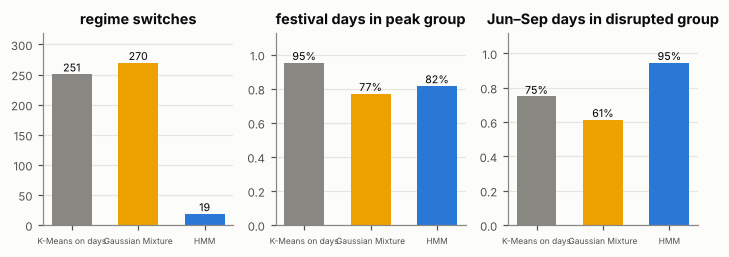

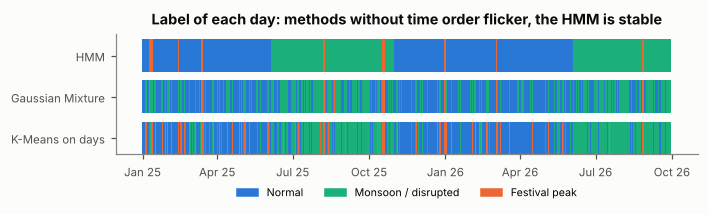

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.4))
names = cmp_days.columns.tolist(); cols = [MUTED, YELLOW, BLUE]
for ax, metric, fmt in zip(axes, ["regime switches", "festival days in peak group", "Jun–Sep days in disrupted group"], ["{:.0f}", "{:.0%}", "{:.0%}"]):
    vals = cmp_days.loc[metric].astype(float).values
    bars = ax.bar(names, vals, color=cols, width=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=7)
    ax.set(title=metric, ylim=(0, max(vals) * 1.18)); ax.grid(axis="x", visible=False); ax.tick_params(axis="x", labelsize=5.5)
plt.tight_layout(); save_fig(fig, "same_data_metrics")

def role_colours(lbl):        # colour each group by its role: peak / disrupted / normal
    lbl = pd.Series(lbl, index=daily.index)
    dem = daily.demand_index.groupby(lbl).mean(); late = daily.late_rate.groupby(lbl).mean()
    top = dem.idxmax(); dis = late.drop(top).idxmax()
    cmap = {g: (SCOL["Festival peak"] if g == top else SCOL["Monsoon / disrupted"] if g == dis else SCOL["Normal"]) for g in dem.index}
    return lbl.map(cmap).values

fig, ax = plt.subplots(figsize=(6.5, 2.1))
for row, (lbl, name) in enumerate([(km_days, "K-Means on days"), (gmm_days, "Gaussian Mixture"), (hmm_days, "HMM")]):
    ax.bar(daily.index, 0.8, bottom=row - 0.4, width=1.0, color=role_colours(lbl), linewidth=0)
ax.set_yticks(range(3)); ax.set_yticklabels(["K-Means on days", "Gaussian Mixture", "HMM"]); ax.grid(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=SCOL[n]) for n in SORDER], labels=SORDER, fontsize=7, ncol=3,
          loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
ax.set_title("Label of each day: methods without time order flicker, the HMM is stable")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
plt.tight_layout(); save_fig(fig, "label_of_each_day")

**Reading the results:** methods that ignore time switch labels very often — a single rainy-looking day flips them.
K-Means catches more festival days only because its "peak" group is large: it also puts 61 ordinary days in it, against
5 for the HMM. The HMM produces long, believable regimes because the transition probabilities make switching costly
unless the evidence is strong, and it explains unseen 2026 days better than the same states without transitions.
The silhouette favours the flickering labels because it ignores time.

## 4.3 Using both together — store cluster × regime

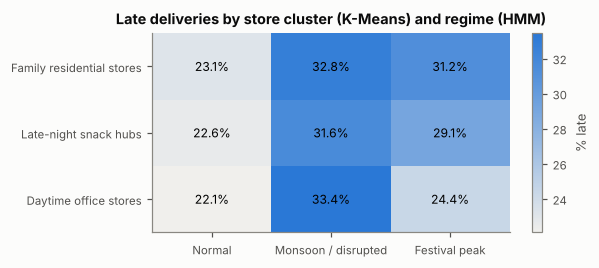

regime,Normal,Monsoon / disrupted,Festival peak
cluster,,,
Family residential stores,23.100,32.800,31.200
Late-night snack hubs,22.600,31.600,29.100
Daytime office stores,22.100,33.400,24.400


In [6]:
both = clean[clean.order_status.ne("Cancelled")].assign(cluster=lambda t: t.store_id.map(stores.cluster),
                                                        regime=lambda t: t.order_date.map(daily.state))
tab = both.pivot_table(index="cluster", columns="regime", values="is_late", aggfunc="mean").reindex(index=ORDER, columns=SORDER) * 100
tab.round(2).to_csv(f"{OUT}/late_rate_by_cluster_and_regime.csv")
fig, ax = plt.subplots(figsize=(5.6, 2.5))
blues = LinearSegmentedColormap.from_list("b", ["#f0efec", BLUE])
im = ax.imshow(tab.values, cmap=blues, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(SORDER, fontsize=7.5); ax.set_yticks(range(3)); ax.set_yticklabels(ORDER, fontsize=7.5)
ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{tab.values[i, j]:.1f}%", ha="center", va="center", fontsize=8)
ax.set_title("Late deliveries by store cluster (K-Means) and regime (HMM)")
fig.colorbar(im, ax=ax, label="% late"); plt.tight_layout(); save_fig(fig, "late_by_cluster_and_regime")
tab.round(1)

The regime changes lateness far more than the store type does (monsoon adds 9–11 points in every cluster). The two
models answer different questions and work best **together**: K-Means says *which kind of store*, the HMM says *which
situation the network is in*.

| Suitability | K-Means | HMM |
|---|---|---|
| Segmenting stores / products / customers | best choice | not suited — needs a time sequence |
| Detecting regimes in a time series | not suited — ignores order, flickers | best choice |
| Forecasting the next regime | not possible | yes — transition matrix |
| Ease of explanation | high — simple averages | moderate — probabilities |
| Training cost | milliseconds | about a second (EM with restarts) |

---
# 5 · Results, Insights and Limitations
### Key findings
1. **Three types of dark store** (K-Means, k = 3): family residential stores, late-night snack hubs and daytime office
   stores. They differ in *when* orders arrive and *which* food is bought, and match location although location was
   not used.
2. **Three hidden demand regimes** (HMM, chosen by BIC): Normal, Monsoon / disrupted and Festival peak. Regimes last
   weeks; festival peaks two to three days; 82% of festival days are detected, with only 5 false peaks.
3. **The regime matters more than the store type for delivery delays.**
4. **Time order adds value:** stable regimes and better out-of-sample likelihood than the same model without
   transitions; static clustering of days flickers.

### Limitations
- The dataset is **synthetic**; the methods are realistic, the numbers are not real business results.
- Categories were filtered by each order's **main** category; a kept order can still contain some non-food items.
- The **IPL correction** assumes IPL only adds evening orders (supported by the data: daytime demand was unchanged).
- Only 58 stores; the office cluster has 5 members.
- The HMM assumes first-order Markov transitions and Gaussian observations.

### Possible improvements
- Real store data from a quick-commerce or retail partner.
- Cluster at product × store level to plan individual SKUs.
- HMM per city or per store cluster; weather and festival calendars as inputs (input–output HMM); more observations.
- Feed the decoded regime into the PBL-1 demand-forecasting model as a feature.

### References
- A. Bharathi S.A., *India Quick Commerce Orders 2025–2026*, Kaggle (CC0) —
  https://www.kaggle.com/datasets/abirambharathisa/india-quick-commerce-orders-2025-2026
- F. Pedregosa et al., "Scikit-learn: Machine Learning in Python", *JMLR* 12, 2011 — https://scikit-learn.org
- hmmlearn: Hidden Markov Models in Python — https://hmmlearn.readthedocs.io
- L. R. Rabiner, "A Tutorial on Hidden Markov Models and Selected Applications in Speech Recognition", *Proc. IEEE* 77(2), 1989.
- P. J. Rousseeuw, "Silhouettes: a graphical aid to the interpretation and validation of cluster analysis", 1987.

In [7]:
for f in sorted(os.listdir(OUT)):
    print(f"{OUT}/{f}")

Unit_4_PBL2_HMM/results/04_comparison/label_of_each_day.png
Unit_4_PBL2_HMM/results/04_comparison/late_by_cluster_and_regime.png
Unit_4_PBL2_HMM/results/04_comparison/late_rate_by_cluster_and_regime.csv
Unit_4_PBL2_HMM/results/04_comparison/same_data_comparison.csv
Unit_4_PBL2_HMM/results/04_comparison/same_data_metrics.png
Unit_4_PBL2_HMM/results/04_comparison/summary_table.csv
